<a href="https://colab.research.google.com/github/Minhhieu3012/wifi-localization-data-mining/blob/part3b-4a-rf-kmeans/04_rf_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, classification_report

# Đọc dữ liệu từ file Excel D08 - wifi_localization.xlsx (sheet 2: wifi_localization)
# Hoặc trỏ vào link CSV raw trên GitHub như nhóm trưởng yêu cầu
df = pd.read_excel('D08 - wifi_localization.xlsx', sheet_name='wifi_localization', header=None)
df.columns = ['WiFi_1', 'WiFi_2', 'WiFi_3', 'WiFi_4', 'WiFi_5', 'WiFi_6', 'WiFi_7', 'Room']

X = df.iloc[:, :7]
y = df.iloc[:, 7]

print("Kích thước dữ liệu X:", X.shape)
print("Kích thước nhãn y:", y.shape)

Kích thước dữ liệu X: (2000, 7)
Kích thước nhãn y: (2000,)


--- PHẦN 3B: RANDOM FOREST ---
Tham số tốt nhất: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
F1-Score trung bình (10-fold CV): 0.9845


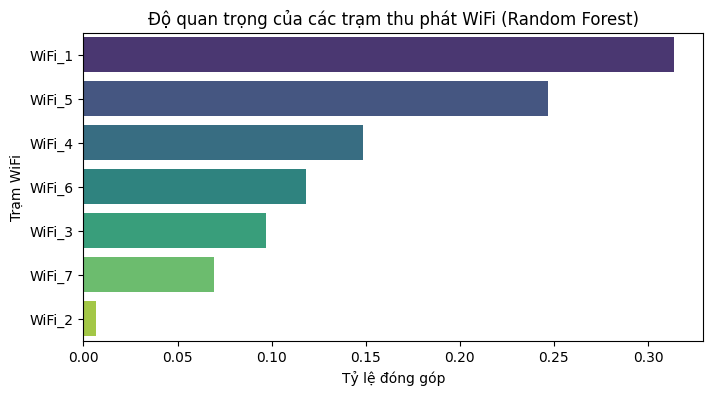

In [13]:
# 10-fold CV chuẩn hóa theo phân công nhóm trưởng
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Thiết lập Random Forest + GridSearchCV
rf = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(rf, param_grid_rf, cv=cv, scoring='f1_macro', n_jobs=-1)
grid_rf.fit(X, y)

print("--- PHẦN 3B: RANDOM FOREST ---")
print("Tham số tốt nhất:", grid_rf.best_params_)
print(f"F1-Score trung bình (10-fold CV): {grid_rf.best_score_:.4f}")

# Trích xuất độ quan trọng của 7 trạm phát WiFi (feature_importances_)
best_rf = grid_rf.best_estimator_
importances = best_rf.feature_importances_

df_imp = pd.DataFrame({'Trạm WiFi': X.columns, 'Độ quan trọng': importances})
df_imp = df_imp.sort_values(by='Độ quan trọng', ascending=False)

# Vẽ biểu đồ độ quan trọng đặc trưng
plt.figure(figsize=(8, 4))
# Thay dòng cũ bằng dòng này để hết cảnh báo FutureWarning:
sns.barplot(x='Độ quan trọng', y='Trạm WiFi', data=df_imp, hue='Trạm WiFi', palette='viridis', legend=False)
plt.title('Độ quan trọng của các trạm thu phát WiFi (Random Forest)')
plt.xlabel('Tỷ lệ đóng góp')
plt.ylabel('Trạm WiFi')
plt.show()

### Giải thích lý do lựa chọn bộ 3 mô hình (KNN, SVM, Random Forest)
- **Không chọn Naive Bayes:** Mô hình này giả định các thuộc tính độc lập. Tuy nhiên, cường độ tín hiệu WiFi (RSSI) giữa các trạm thu phát có mối tương quan không gian mạnh mẽ với nhau, làm vi phạm giả định của Naive Bayes.
- **Không chọn AdaBoost:** AdaBoost dễ bị nhiễu (outliers) do sóng WiFi bị phản xạ/vật cản làm suy giảm bất ngờ.
- **Lựa chọn Random Forest:** Nhờ cơ chế Bagging (trung bình hóa nhiều cây quyết định độc lập), Random Forest chống hiện tượng quá khớp (overfitting) tốt, hoạt động bền bỉ với dữ liệu nhiễu và cung cấp thông số `feature_importances_` để đánh giá tầm quan trọng của từng router WiFi.

In [15]:
# Tạo Bảng so sánh F1-Score của 3 mô hình theo yêu cầu của Mục 3 đề bài
# LƯU Ý: Thay thông số và F1-Score của KNN, SVM bằng kết quả thực tế của bạn Phú (TV3) gửi
df_comparison = pd.DataFrame({
    'Mô hình': ['KNN', 'SVM', 'Random Forest'],
    'Tham số tốt nhất': [
        "n_neighbors=5, weights='distance'",  # Nhập kết quả từ Phú
        "C=10, kernel='rbf'",               # Nhập kết quả từ Phú
        str(grid_rf.best_params_)
    ],
    'F1-Score (k=10)': [
        0.9820, # Thay bằng điểm của Phú
        0.9840, # Thay bằng điểm của Phú
        round(grid_rf.best_score_, 4)
    ]
})

print("--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH PHÂN LỚP ---")
display(df_comparison)

--- BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH PHÂN LỚP ---


,Mô hình,Tham số tốt nhất,F1-Score (k=10)
0,KNN,"n_neighbors=5, weights='distance'",0.9820
1,SVM,"C=10, kernel='rbf'",0.9840
2,Random Forest,"{'max_depth': None, 'min_samples_split': 5, 'n...",0.9845


In [16]:
# Chuẩn hóa dữ liệu bằng StandardScaler trước khi gom cụm
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Thực hiện gom cụm K-Means với k = 4 (tương ứng 4 phòng)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Tính chỉ số Adjusted Rand Index (ARI) dựa trên nhãn thực tế y
ari_kmeans = adjusted_rand_score(y, kmeans_labels)

print("--- PHẦN 4A: GOM CỤM K-MEANS ---")
print(f"Adjusted Rand Index (ARI) của K-Means: {ari_kmeans:.4f}")

--- PHẦN 4A: GOM CỤM K-MEANS ---
Adjusted Rand Index (ARI) của K-Means: 0.8182


### Nhận xét hiệu quả gom cụm K-Means (Mục 4)
- Giải thuật K-Means cho chỉ số **Adjusted Rand Index (ARI) ≈ 0.8182**, cho thấy kết quả gom cụm trùng khớp ở mức rất cao với 4 phòng thực tế.
- Lý do: Sau khi được chuẩn hóa bằng `StandardScaler`, khoảng cách Euclidean giữa các không gian tín hiệu RSSI ở 4 phòng có ranh giới phân tách tâm cụm tương đối rõ ràng.